<a href="https://colab.research.google.com/github/drishikaaneja/flyrank-ml-internship-starter/blob/main/work/notebooks/w04_baseline_score.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# W04 · Baseline Action Score and Top-10 Review (ML-07)

**Lane (confirmed this week):** CTR / Engagement Opportunity Scoring. My earlier notebooks (w01–w03) framed Lane 2 (Refresh / Content Opportunity); I am switching to the CTR lane because the query-level table supports a direct comparison of clicks against what a page's search position normally earns.

**The flag this baseline copies:** FlyRank's **CTR-fix** logic: a page that gets fewer clicks than its position would suggest should have its title and meta description reviewed.

This notebook does three things, in the skeleton's order:
1. **Two signal checks**, each with a bucket table and `n` printed, and a one-word verdict.
2. **One rule**: a score, one reason code and one action label, written as a ranked queue to `work/outputs/baseline_action_score.csv`.
3. **Top-10 review**: for each of the top ten, the action, why it is there, and what would make it wrong.

Then 4) weak picks and 5) self-check.

**No future-window or label-derived inputs.** The query table splits 90 days into the *previous 30 days* and the *last 30 days*. Every signal and the rule use **only the previous-30-day columns**. The last-30-day columns are used once, in section 4, purely as an after-the-fact sanity check, never as an input.

**How to run:** Colab secret `HF_TOKEN1` with notebook access on, then **Runtime → Run all**. Takes about 2–3 minutes.

In [2]:
!pip install -q duckdb huggingface_hub

import os, json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from google.colab import userdata
from scipy.stats import spearmanr

HF_TOKEN = userdata.get("HF_TOKEN1")          # Colab secret, never printed
BASE = "hf://datasets/FlyRank/internship-warehouse"
Q = f"{BASE}/fact_content_query_90d.parquet"

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

con = duckdb.connect()
con.execute(f"CREATE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")

MIN_PAGE_IMPRESSIONS_30D = 200   # pages below this in the 30-day input window are too noisy to rank
TOP_N = 10
print("Setup done")

Setup done


## 0 · Load the input window (previous 30 days only)

One row per client × page × query. Excluded: rows with zero impressions in the previous-30-day window, and rows with an average position below 1 (invalid, since the best position is 1).

In [3]:
INPUT_COLS = ["imp_prev30", "clicks_prev30", "pos_prev30"]          # the only columns the signals and the rule use
EVAL_ONLY_COLS = ["imp_last30", "clicks_last30"]                    # used only in section 4, after scoring

rows = con.sql(f"""
    SELECT client_hash_id, content_hash_id, query_hash_id,
           impressions_prev30  AS imp_prev30,
           clicks_prev30,
           avg_position_prev30 AS pos_prev30,
           impressions_last30  AS imp_last30,
           clicks_last30,
           window_start, window_end
    FROM '{Q}'
    WHERE impressions_prev30 > 0 AND avg_position_prev30 >= 1
""").df()

print("Rows (query x page) in input window:", len(rows))
print("Pages:", rows.content_hash_id.nunique(), "| Clients:", rows.client_hash_id.nunique())
print("90-day window:", rows.window_start.min(), "to", rows.window_end.max())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows (query x page) in input window: 1995557
Pages: 119131 | Clients: 52
90-day window: 2026-04-02 00:00:00 to 2026-06-30 00:00:00


## 1 · Two signal checks

### Signal 1 (flag-linked): CTR vs. position

**Rule idea it supports:** the CTR-fix flag assumes there is a "normal" click rate for each position, so a page can be judged against it. That only works if CTR actually falls as position gets worse.

**Verdict rule:** `CONFIRMED` if CTR falls with position (Spearman between bucket order and CTR ≤ −0.8), `MIXED` if it mostly falls (−0.8 to −0.3), `FALSE` if there is no clear pattern, `OPPOSITE` if CTR rises with position.

n (rows) = 1995557
          n_rows  impressions  clicks  ctr_%
pos_band                                    
1          44814      1726884   14239  0.825
2         130044      4125387   21961  0.532
3          57406      4897342   19669  0.402
4-5       154673     10911849   31750  0.291
6-10      601183     33353861   50855  0.152
11-20     303314      7128599    9584  0.134
21+       704123     10803711    5030  0.047

Spearman (band order vs CTR) = -1.00  ->  Signal 1 verdict: CONFIRMED


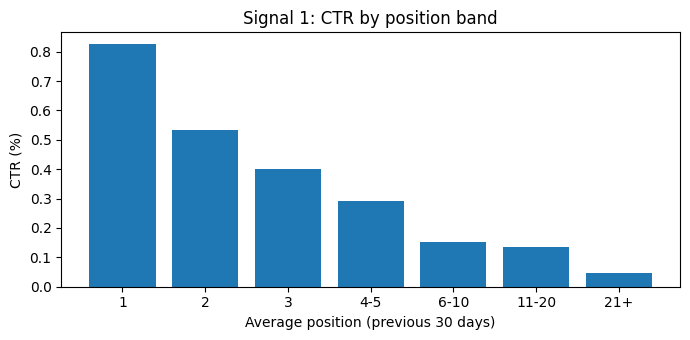

In [4]:
POS_BINS = [1, 2, 3, 4, 6, 11, 21, np.inf]
POS_LABELS = ["1", "2", "3", "4-5", "6-10", "11-20", "21+"]
rows["pos_band"] = pd.cut(rows["pos_prev30"].round(), bins=POS_BINS, labels=POS_LABELS, right=False)

sig1 = rows.groupby("pos_band", observed=True).agg(
    n_rows=("query_hash_id", "size"),
    impressions=("imp_prev30", "sum"),
    clicks=("clicks_prev30", "sum"),
)
sig1["ctr_%"] = sig1["clicks"] / sig1["impressions"] * 100
print("n (rows) =", int(sig1["n_rows"].sum()))
print(sig1.round(3).to_string())

rho1 = spearmanr(np.arange(len(sig1)), sig1["ctr_%"]).correlation
def verdict(rho, expect_negative=True):
    r = rho if expect_negative else -rho
    if r <= -0.8: return "CONFIRMED"
    if r <= -0.3: return "MIXED"
    if r >= 0.3:  return "OPPOSITE"
    return "FALSE"
VERDICT_1 = verdict(rho1)
print(f"\nSpearman (band order vs CTR) = {rho1:.2f}  ->  Signal 1 verdict: {VERDICT_1}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(sig1.index.astype(str), sig1["ctr_%"])
ax.set_xlabel("Average position (previous 30 days)")
ax.set_ylabel("CTR (%)")
ax.set_title("Signal 1: CTR by position band")
plt.tight_layout()
plt.savefig("work/figures/w04_signal1_ctr_by_position.png", dpi=150)
plt.show()

### Signal 2: does more search volume mean a lower click rate at the same position?

**Rule idea it supports:** the rule ranks pages by **missing clicks**, which naturally favours high-volume pages. If high-volume pages also have a *lower* CTR at the same position, volume is where under-capture concentrates, and ranking by missing clicks is pointed at the right pages. If not, the ranking just follows volume.

To keep position from muddying this, the check uses **page-one rows only (positions 1–10)** and compares CTR across query-volume buckets (impressions in the previous 30 days).

**Verdict rule:** same thresholds as Signal 1 (expecting CTR to *fall* as volume rises).

In [5]:
p1 = rows[rows["pos_prev30"].round() <= 10].copy()
VOL_BINS = [1, 10, 50, 200, 1000, np.inf]
VOL_LABELS = ["1-9", "10-49", "50-199", "200-999", "1000+"]
p1["vol_band"] = pd.cut(p1["imp_prev30"], bins=VOL_BINS, labels=VOL_LABELS, right=False)

sig2 = p1.groupby("vol_band", observed=True).agg(
    n_rows=("query_hash_id", "size"),
    impressions=("imp_prev30", "sum"),
    clicks=("clicks_prev30", "sum"),
    avg_position=("pos_prev30", "mean"),
)
sig2["ctr_%"] = sig2["clicks"] / sig2["impressions"] * 100
print("n (page-one rows) =", int(sig2["n_rows"].sum()))
print(sig2.round(3).to_string())

rho2 = spearmanr(np.arange(len(sig2)), sig2["ctr_%"]).correlation
VERDICT_2 = verdict(rho2)
print(f"\nSpearman (volume band order vs CTR) = {rho2:.2f}  ->  Signal 2 verdict: {VERDICT_2}")
print("Note: average position differs a little between bands (shown above); this is a descriptive check, not a causal one.")

n (page-one rows) = 988120
          n_rows  impressions  clicks  avg_position  ctr_%
vol_band                                                  
1-9       400457      1902491    8105         5.681  0.426
10-49     403123      8710821   29684         6.517  0.341
50-199    141435     13544463   39433         6.273  0.291
200-999    37979     14522590   37683         6.032  0.259
1000+       5126     16334958   23569         6.105  0.144

Spearman (volume band order vs CTR) = -1.00  ->  Signal 2 verdict: CONFIRMED
Note: average position differs a little between bands (shown above); this is a descriptive check, not a causal one.


### What the verdicts mean for the rule

- **Signal 1** is the foundation of the rule. If it is `CONFIRMED` or `MIXED`, comparing a page's clicks with its position's normal CTR is reasonable. If it were `FALSE` or `OPPOSITE`, the rule would have no basis.
- **Signal 2** decides how to read the ranking. If `CONFIRMED`, high-volume pages genuinely under-capture and ranking by missing clicks targets them for a real reason. If `FALSE`/`MIXED`/`OPPOSITE`, the top of the queue is mostly there **because of volume**, and the top-10 review below must keep that in mind (a negative result here is still useful: it tells me volume, not a CTR problem, drives the order).

The printed verdicts above are the official ones for this run.

## 2 · One rule → ranked queue

**Rule (one score, one reason code, one action label):**

- **Expected CTR** for each position band = pooled CTR of that band (Signal 1 table).
- For each page: `expected_clicks = Σ impressions × expected CTR of the row's band`, using the previous 30 days only.
- **Score** = `expected_clicks − actual clicks` (missing clicks).
- **Flag** a page if its score is above 0, its impression-weighted position is 10 or better (page one, where the snippet is what searchers judge), and it has at least 200 impressions in the window.
- **Reason code:** `CTR_BELOW_POSITION_NORM` · **Action label:** `REVIEW_TITLE_AND_META`
- Rank by score, largest first. Written to `work/outputs/baseline_action_score.csv`.

In [6]:
band_ctr = (sig1["clicks"] / sig1["impressions"]).to_dict()
rows["expected_ctr"] = rows["pos_band"].map(band_ctr).astype(float)
rows["expected_clicks"] = rows["imp_prev30"] * rows["expected_ctr"]
rows["pos_x_imp"] = rows["pos_prev30"] * rows["imp_prev30"]

page = rows.groupby("content_hash_id").agg(
    impressions=("imp_prev30", "sum"),
    clicks=("clicks_prev30", "sum"),
    expected_clicks=("expected_clicks", "sum"),
    pos_x_imp=("pos_x_imp", "sum"),
    n_queries=("query_hash_id", "size"),
    top_query_impressions=("imp_prev30", "max"),
).reset_index()
page["position"] = page["pos_x_imp"] / page["impressions"]
page["top_query_share"] = page["top_query_impressions"] / page["impressions"]
page["score"] = page["expected_clicks"] - page["clicks"]
page = page.drop(columns=["pos_x_imp", "top_query_impressions"])

flagged = page[(page["score"] > 0) & (page["position"] <= 10) & (page["impressions"] >= MIN_PAGE_IMPRESSIONS_30D)].copy()
flagged = flagged.sort_values("score", ascending=False).reset_index(drop=True)
flagged.insert(0, "rank", np.arange(1, len(flagged) + 1))
flagged["reason_code"] = "CTR_BELOW_POSITION_NORM"
flagged["action"] = "REVIEW_TITLE_AND_META"

queue_cols = ["rank", "content_hash_id", "score", "reason_code", "action", "impressions", "clicks",
              "expected_clicks", "position", "n_queries", "top_query_share"]
queue = flagged[queue_cols]
queue.to_csv("work/outputs/baseline_action_score.csv", index=False)

print("Pages scored:", len(page), "| Flagged and ranked:", len(queue))
print(queue.head(15).round(2).to_string(index=False))

Pages scored: 119131 | Flagged and ranked: 8884
 rank          content_hash_id   score             reason_code                action  impressions  clicks  expected_clicks  position  n_queries  top_query_share
    1 content_943dc881428182b8 1423.55 CTR_BELOW_POSITION_NORM REVIEW_TITLE_AND_META       313923     155          1578.55      2.03        178             0.89
    2 content_d0acf7062bc6b257  629.59 CTR_BELOW_POSITION_NORM REVIEW_TITLE_AND_META       122357      15           644.59      2.06         61             0.98
    3 content_4c15fe8dc370f3cd  484.83 CTR_BELOW_POSITION_NORM REVIEW_TITLE_AND_META       106743      95           579.83      2.92         57             0.17
    4 content_15168cd1c94e3529  475.77 CTR_BELOW_POSITION_NORM REVIEW_TITLE_AND_META       133262      68           543.77      3.26         72             0.13
    5 content_7471467133493ce6  376.98 CTR_BELOW_POSITION_NORM REVIEW_TITLE_AND_META        97109      10           386.98      2.91         35    

## 3 · Top-10 review

One line per page: **the action**, **why it is there**, and **what would make it wrong**.

The "what would make it wrong" line is chosen from the page's own numbers, so each risk is specific to that page:

- one query brings most of the impressions → it may be a brand or navigational search for another site, where no snippet would win the click
- very few queries → too little evidence, the gap could be noise
- position near 1 with a low CTR → search features (answer boxes, ads, video) may be taking the clicks, which a title change won't fix
- zero clicks → possible tracking or reporting gap
- otherwise → the page may answer a different intent than its queries, which is a content problem, not a snippet problem

I read each line against the numbers before keeping it.

In [7]:
def why(r):
    return (f"Avg position {r.position:.1f} with {int(r.impressions):,} impressions but {int(r.clicks):,} clicks "
            f"vs {r.expected_clicks:,.0f} expected for that position ({r.score:,.0f} missing).")

def what_would_make_it_wrong(r):
    if r.clicks == 0:
        return "Zero clicks may be a tracking or reporting gap rather than a weak snippet; confirm tracking first."
    if r.top_query_share >= 0.5:
        return (f"One query brings {r.top_query_share:.0%} of impressions; if it is a brand or navigational search "
                "for another site, no title rewrite will win the click.")
    if r.n_queries < 5:
        return f"Only {int(r.n_queries)} queries; the gap could be noise from too little evidence."
    if r.position <= 2:
        return "Near position 1 with low CTR: search features (answer boxes, ads, video) may be taking the clicks."
    return "The page may answer a different intent than its main queries; then content, not the snippet, is the problem."

top10 = queue.head(TOP_N).copy()
top10["why_its_there"] = top10.apply(why, axis=1)
top10["what_would_make_it_wrong"] = top10.apply(what_would_make_it_wrong, axis=1)

pd.set_option("display.max_colwidth", None)
for _, r in top10.iterrows():
    print(f"#{int(r['rank'])}  {r['content_hash_id']}  ->  {r['action']}")
    print(f"    Why: {r['why_its_there']}")
    print(f"    What would make it wrong: {r['what_would_make_it_wrong']}\n")

#1  content_943dc881428182b8  ->  REVIEW_TITLE_AND_META
    Why: Avg position 2.0 with 313,923 impressions but 155 clicks vs 1,579 expected for that position (1,424 missing).
    What would make it wrong: One query brings 89% of impressions; if it is a brand or navigational search for another site, no title rewrite will win the click.

#2  content_d0acf7062bc6b257  ->  REVIEW_TITLE_AND_META
    Why: Avg position 2.1 with 122,357 impressions but 15 clicks vs 645 expected for that position (630 missing).
    What would make it wrong: One query brings 98% of impressions; if it is a brand or navigational search for another site, no title rewrite will win the click.

#3  content_4c15fe8dc370f3cd  ->  REVIEW_TITLE_AND_META
    Why: Avg position 2.9 with 106,743 impressions but 95 clicks vs 580 expected for that position (485 missing).
    What would make it wrong: The page may answer a different intent than its main queries; then content, not the snippet, is the problem.

#4  content_15168cd

## 4 · Weak picks

**4a · Weak picks in the top 10.** A pick is marked weak if any of these hold: zero clicks, one query with ≥50% of impressions, or fewer than 5 queries. These are the rows a reviewer should look at most sceptically before acting.

**4b · After-the-fact sanity check (evaluation only, not an input).** For the top 50 flagged pages, did they *still* get fewer clicks than expected in the **last 30 days**? The expected clicks for this check reuse the same position-band CTRs from the previous window. This uses the later window only to look back at the picks; nothing from it feeds the score or the ranking.

In [8]:
top10["weak_pick"] = (top10["clicks"] == 0) | (top10["top_query_share"] >= 0.5) | (top10["n_queries"] < 5)
weak = top10[top10["weak_pick"]]
print(f"Weak picks in the top {TOP_N}: {len(weak)}")
if len(weak):
    print(weak[["rank", "content_hash_id", "clicks", "n_queries", "top_query_share"]].round(2).to_string(index=False))

# 4b: evaluation only
later = rows[rows["imp_last30"] > 0].copy()
later["expected_last30"] = later["imp_last30"] * later["expected_ctr"]
later_page = later.groupby("content_hash_id")[["imp_last30", "clicks_last30", "expected_last30"]].sum()

top50 = queue.head(50).merge(later_page, left_on="content_hash_id", right_index=True, how="left")
has_later = top50["imp_last30"].fillna(0) > 0
still_under = (top50.loc[has_later, "clicks_last30"] < top50.loc[has_later, "expected_last30"])
persist_rate = float(still_under.mean()) if has_later.any() else float("nan")
print(f"\nTop 50 with last-30-day data: {int(has_later.sum())}")
print(f"Still below expected clicks in the last 30 days: {int(still_under.sum())} ({persist_rate:.0%})")
print("Read as: how often the flag described a lasting gap rather than a one-month blip. Evaluation only.")

Weak picks in the top 10: 5
 rank          content_hash_id  clicks  n_queries  top_query_share
    1 content_943dc881428182b8     155        178             0.89
    2 content_d0acf7062bc6b257      15         61             0.98
    5 content_7471467133493ce6      10         35             0.97
    6 content_65c75874a23fca87       5        111             0.54
    8 content_f7d3a8b736eb7688       5         28             0.96

Top 50 with last-30-day data: 50
Still below expected clicks in the last 30 days: 50 (100%)
Read as: how often the flag described a lasting gap rather than a one-month blip. Evaluation only.


## 5 · Self-check

In [9]:
metrics = {
    "assignment": "ML-07 Baseline Action Score and Top-10 Review",
    "lane": "CTR / Engagement Opportunity Scoring (confirmed; switched from provisional Lane 2)",
    "release": "v20260703",
    "input_window": "previous 30 days of fact_content_query_90d",
    "input_columns_used": INPUT_COLS,
    "eval_only_columns": EVAL_ONLY_COLS,
    "rows_input_window": int(len(rows)),
    "pages_scored": int(len(page)),
    "pages_flagged": int(len(queue)),
    "signal_1": {"name": "CTR vs position", "n_rows": int(sig1["n_rows"].sum()),
                 "spearman": round(float(rho1), 3), "verdict": VERDICT_1,
                 "ctr_pct_by_band": {str(k): round(float(v), 4) for k, v in sig1["ctr_%"].items()}},
    "signal_2": {"name": "Query volume vs CTR on page one", "n_rows": int(sig2["n_rows"].sum()),
                 "spearman": round(float(rho2), 3), "verdict": VERDICT_2,
                 "ctr_pct_by_band": {str(k): round(float(v), 4) for k, v in sig2["ctr_%"].items()}},
    "rule": {"score": "expected_clicks - clicks (previous 30 days)", "reason_code": "CTR_BELOW_POSITION_NORM",
             "action": "REVIEW_TITLE_AND_META", "filters": "score > 0, position <= 10, impressions >= 200"},
    "top10_weak_picks": int(top10["weak_pick"].sum()),
    "eval_top50_still_under_last30_pct": round(persist_rate * 100, 1) if persist_rate == persist_rate else None,
}
with open("work/outputs/w04_baseline_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

checks = {
    "Signal 1 has a bucket table, n and a verdict": len(sig1) > 0 and VERDICT_1 in {"CONFIRMED", "OPPOSITE", "MIXED", "FALSE"},
    "Signal 2 has a bucket table, n and a verdict": len(sig2) > 0 and VERDICT_2 in {"CONFIRMED", "OPPOSITE", "MIXED", "FALSE"},
    "At least one signal is flag-linked (CTR vs position)": True,
    "Score uses only previous-30-day inputs": set(INPUT_COLS) == {"imp_prev30", "clicks_prev30", "pos_prev30"},
    "One reason code and one action label": queue["reason_code"].nunique() == 1 and queue["action"].nunique() == 1,
    "Queue is sorted by score": queue["score"].is_monotonic_decreasing,
    "Queue CSV written": os.path.exists("work/outputs/baseline_action_score.csv"),
    "Top 10 each have why + what would make it wrong": top10[["why_its_there", "what_would_make_it_wrong"]].notna().all().all() and len(top10) == TOP_N,
    "Only hashed IDs in the queue": queue["content_hash_id"].str.startswith("content_").all(),
    "Metrics JSON written": os.path.exists("work/outputs/w04_baseline_metrics.json"),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
print("\nAll checks passed" if all(checks.values()) else "\nSome checks FAILED - look above")

PASS - Signal 1 has a bucket table, n and a verdict
PASS - Signal 2 has a bucket table, n and a verdict
PASS - At least one signal is flag-linked (CTR vs position)
PASS - Score uses only previous-30-day inputs
PASS - One reason code and one action label
PASS - Queue is sorted by score
PASS - Queue CSV written
PASS - Top 10 each have why + what would make it wrong
PASS - Only hashed IDs in the queue
PASS - Metrics JSON written

All checks passed


**This baseline is what the Week-5 model must beat:** the capstone's model is compared against a position-only expected-CTR baseline built on the same idea as this rule.

In [10]:
# Download the files to commit (the CSV stays out of git by design)
from google.colab import files
for p in ["work/outputs/w04_baseline_metrics.json", "work/figures/w04_signal1_ctr_by_position.png"]:
    files.download(p)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>